Best accuracy: 55.60925000 at epoch: 45 with CR: 0.93535093
Best accuracy: 55.62651000 at epoch: 15 with CR: 0.99527091
Best accuracy: 55.62651000 at epoch: 6 with CR: 1.00743293
Best accuracy: 55.62651000 at epoch: 76 with CR: 1.03182784


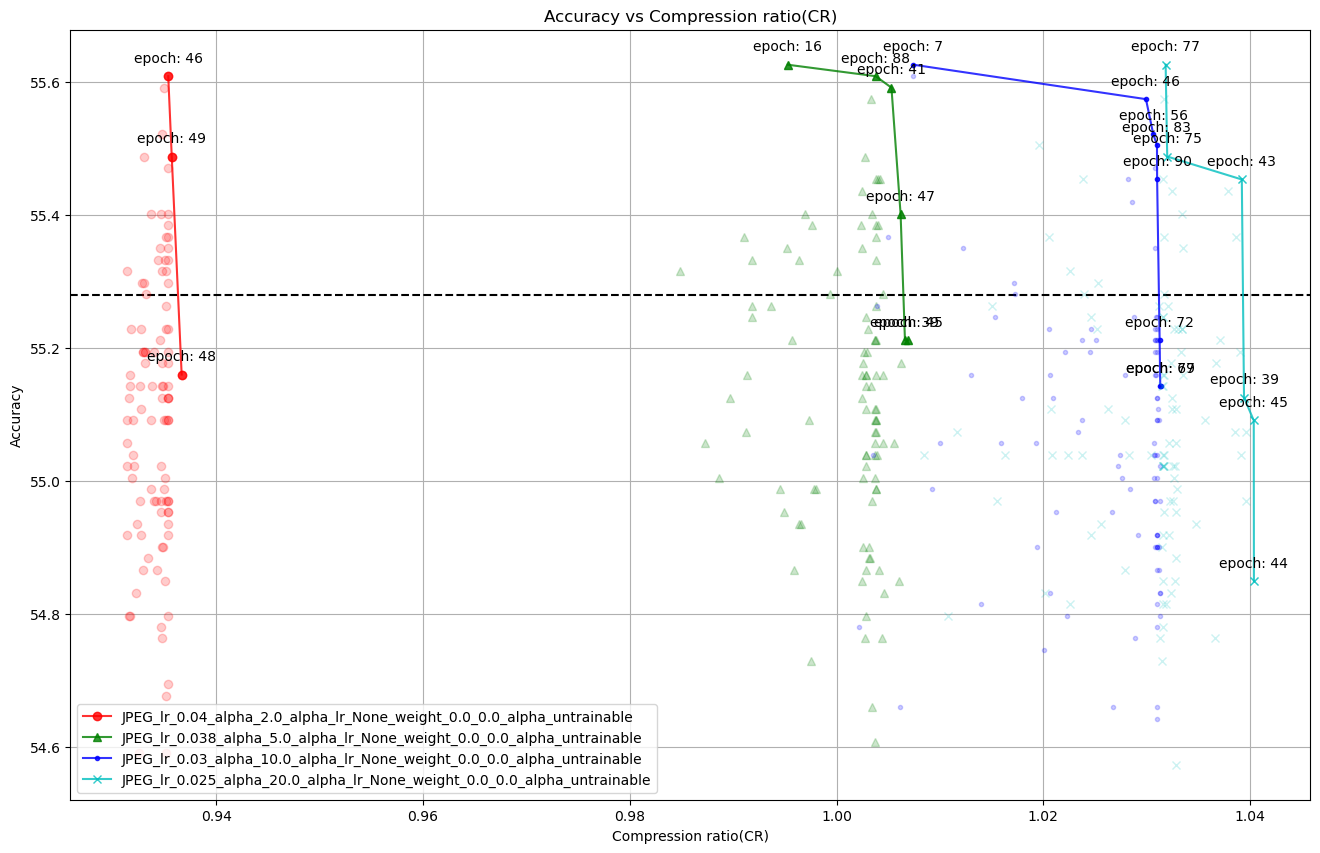

In [13]:
import matplotlib.pyplot as plt
import os


def read_file(file_path):
    data = []
    with open(file_path, 'r') as file:
        for line in file:
            parts = line.split()
            if len(parts) == 16:
                row = list(map(float, parts))
                data.append(row)
    return data


def get_greedy(x_values, y_values):
    # Sort data by y_values while keeping x_values in corresponding order
    sorted_pairs = sorted(zip(y_values, x_values,range(len(y_values))), key=lambda x: x[0], reverse=True)
    sorted_y_values, sorted_x_values, sorted_index = zip(*sorted_pairs)  # Unzip pairs into separate lists

    best_y = sorted_y_values[0]
    best_x = sorted_x_values[0]
    print("Best accuracy: {y:.8f} at epoch: {index:.0f} with CR: {x:.8f}".format(y=best_y, index=sorted_index[0], x=best_x))
    
    new_y = []
    new_x = []
    new_index = []
    
    for index, y_value in enumerate(sorted_y_values):
        if sorted_x_values[index] >= best_x and y_value <= best_y:
            best_x = sorted_x_values[index]
            best_y = y_value
            new_y.append(y_value)
            new_x.append(sorted_x_values[index])
            new_index.append(sorted_index[index])
    
    return new_x, new_y, new_index


def plot_data(file_path, marker, label, color, greedy=True):
    data = read_file(file_path)
    y_values = [row[2] for row in data] # test acc
    x_values = [269.63494 / (row[6] + row[7] + row[8] + row[9]) for row in data] # entropy
    # x_values = [row[4] for row in data] # test loss
    
    if greedy:
        new_x_values, new_y_values, new_index = get_greedy(x_values, y_values)
        
        plt.plot(x_values, y_values, marker=marker, color=color, alpha=0.2, linestyle="")
        plt.plot(new_x_values, new_y_values, marker=marker, label=label, color=color, alpha=0.8)
    
        for i, (x, y) in enumerate(zip(new_x_values, new_y_values)):
            plt.annotate("epoch: " + str(new_index[i]+1),  # Text to display
                        (x, y),          # Point to annotate
                        textcoords="offset points",  # How to position the text
                        xytext=(0,10),   # Distance from text to points (x,y)
                        ha='center')     # Horizontal alignment can be left, right or center    
    else:
        plt.plot(x_values, y_values, marker=marker, label=label, linestyle="", color=color, alpha=0.5)


def plot_data_average(base_path):
    total_y_sums = []
    total_x_sums = []
    
    file_count = 0
    for trial_folder in os.listdir(base_path):
        folder_path = os.path.join(base_path, trial_folder)
        if os.path.isdir(folder_path):  # 确保是文件夹
            log_file_path = os.path.join(folder_path, 'logs.txt')
            print(log_file_path)
            if os.path.exists(log_file_path):
                data = read_file(log_file_path)
                y_values = [row[2] for row in data] # test acc
                x_values = [row[6] + row[7] + row[8] + row[9] for row in data] # entropy
                print(len(x_values))
                if not total_y_sums:
                    total_y_sums = y_values
                    total_x_sums = x_values
                else:
                    total_y_sums = [sum(x) for x in zip(total_y_sums, y_values)]
                    total_x_sums = [sum(x) for x in zip(total_x_sums, x_values)]
                file_count += 1
    if file_count > 0:
        average_y = [y / file_count for y in total_y_sums]
        average_x = [x / file_count for x in total_x_sums]
    
    print(len(average_x))
    plt.plot(average_x, average_y, marker="^", label='JPEG_lr_0.01_alpha_100.0')


plt.figure(figsize=(16, 10))
plt.axhline(y=55.28, color='black', linestyle='--') # baseline

cl = ['r','g','b','c','m','y','k'] # color_list
base_path = './save/CUB200/resnet18'

file_name_1 = "JPEG_lr_0.04_alpha_2.0_alpha_lr_None_weight_0.0_0.0_alpha_untrainable"
file_name_2 = "JPEG_lr_0.038_alpha_5.0_alpha_lr_None_weight_0.0_0.0_alpha_untrainable"
file_name_3 = "JPEG_lr_0.03_alpha_10.0_alpha_lr_None_weight_0.0_0.0_alpha_untrainable"
file_name_4 = "JPEG_lr_0.025_alpha_20.0_alpha_lr_None_weight_0.0_0.0_alpha_untrainable"
file_name_5 = "JPEG_lr_0.008_alpha_200.0_alpha_lr_None_weight_0.1_0.1_alpha_untrainable"
file_name_6 = "JPEG_lr_0.01_alpha_100.0_alpha_lr_None_weight_0.1_0.1_alpha_untrainable"

plot_data(os.path.join(os.path.join(base_path, file_name_1), "trial_1/logs.txt"), 'o', file_name_1, color=cl[0])
plot_data(os.path.join(os.path.join(base_path, file_name_2), "trial_1/logs.txt"), '^', file_name_2, color=cl[1])
plot_data(os.path.join(os.path.join(base_path, file_name_3), "trial_1/logs.txt"), '.', file_name_3, color=cl[2])
plot_data(os.path.join(os.path.join(base_path, file_name_4), "trial_1/logs.txt"), 'x', file_name_4, color=cl[3])
# plot_data(os.path.join(os.path.join(base_path, file_name_5), "trial_1/logs.txt"), 'v', file_name_5, color=cl[4])
# plot_data(os.path.join(os.path.join(base_path, file_name_6), "trial_1/logs.txt"), '>', file_name_6, color=cl[5])

# plot_data_average('./save/CUB200/resnet18/JPEG_lr_0.04_alpha_2.0_alpha_lr_None_weight_0.5_0.5_alpha_untrainable')

plt.xlabel('Compression ratio(CR)')
plt.ylabel('Accuracy')
plt.title('Accuracy vs Compression ratio(CR)')
plt.legend()
plt.grid(True)
plt.show()
    

100
100
100


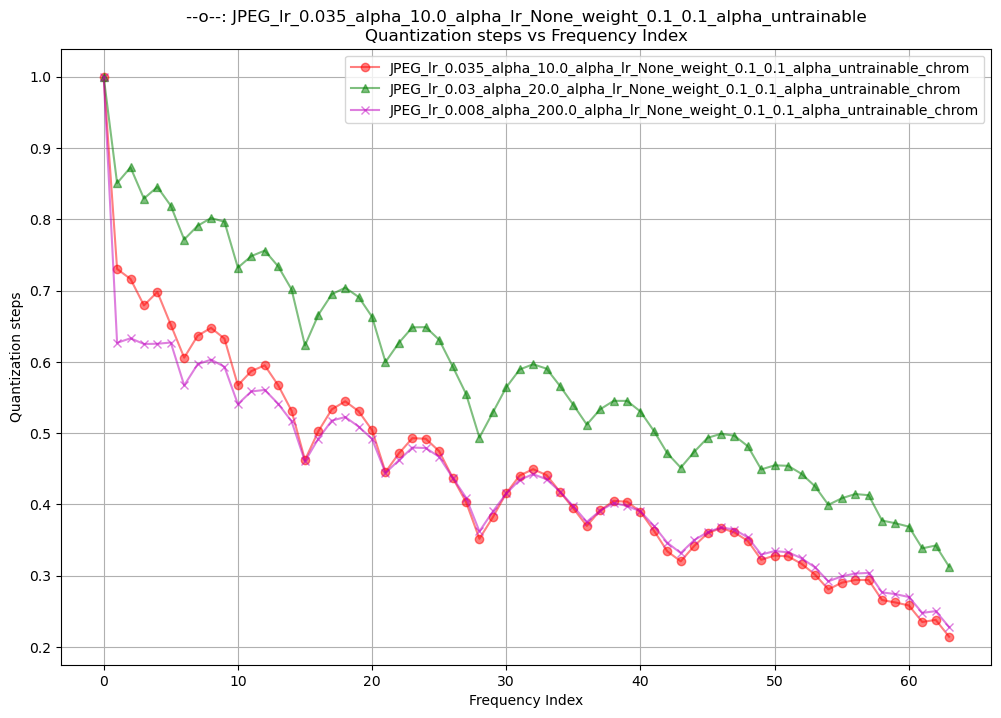

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import os

def zigzag(matrix):
    zigzag = np.array([[0, 1, 5, 6, 14, 15, 27, 28],
                        [2, 4, 7, 13, 16, 26, 29, 42],
                        [3, 8, 12, 17, 25, 30, 41, 43],
                        [9, 11, 18, 24, 31, 40, 44, 53],
                        [10, 19, 23, 32, 39, 45, 52, 54],
                        [20, 22, 33, 38, 46, 51, 55, 60],
                        [21, 34, 37, 47, 50, 56, 59, 61],
                        [35, 36, 48, 49, 57, 58, 62, 63]])

    # Get the shape of the matrix
    matrix_size = np.shape(matrix)
    
    # Calculate the size of the vector
    vector_size = np.shape(zigzag)
    
    # Check if the matrix size matches the vector size
    if matrix_size != vector_size:
        raise ValueError("The matrix size does not match the vector size.")

    # Create an empty vector to store the values
    vector = np.zeros(matrix_size[0] * matrix_size[1])

    # Iterate over each element in the matrix and place it in the corresponding position in the vector
    for i in range(matrix_size[0]):
        for j in range(matrix_size[1]):
            index = zigzag[i, j]
            vector[index] = matrix[i, j]

    return vector


def plot_q_table(filepaths, marker, color, label, epoch_choose=0 ):
    with open(filepaths, "r") as file:
        lines = file.read()

    q_tables = lines.split("\n\n")[:-1]
    print(len(q_tables))
    
    for epoch, q_table in enumerate(q_tables):
        # if epoch % 10 != 0 and epoch != 99:
        #     continue
        if epoch != epoch_choose:
            continue
        matrix = np.array([list(map(float, row.split(","))) for row in q_table.split("\n")])
        matrix = zigzag(matrix).flatten()
        dc = matrix[0]
        plt.plot(matrix/dc, marker=marker, color=color, label=label, alpha=0.5)
        
cl = ['r','g','b','c','m','y','k'] # color_list

base_path = './save/CUB200/resnet18'

file_name_1 = "JPEG_lr_0.035_alpha_10.0_alpha_lr_None_weight_0.1_0.1_alpha_untrainable"
file_name_2 = "JPEG_lr_0.03_alpha_20.0_alpha_lr_None_weight_0.1_0.1_alpha_untrainable"
file_name_3 = "JPEG_lr_0.02_alpha_50.0_alpha_lr_None_weight_0.1_0.1_alpha_untrainable"
file_name_4 = "JPEG_lr_0.01_alpha_100.0_alpha_lr_None_weight_0.1_0.1_alpha_untrainable"
file_name_5 = "JPEG_lr_0.008_alpha_200.0_alpha_lr_None_weight_0.1_0.1_alpha_untrainable"

logs_path_1 = os.path.join(os.path.join(base_path, file_name_1), "trial_1/Q_tables/lum_q_table.txt")
logs_path_2 = os.path.join(os.path.join(base_path, file_name_1), "trial_1/Q_tables/chrom_q_table.txt")
logs_path_3 = os.path.join(os.path.join(base_path, file_name_2), "trial_1/Q_tables/lum_q_table.txt")
logs_path_4 = os.path.join(os.path.join(base_path, file_name_2), "trial_1/Q_tables/chrom_q_table.txt")
logs_path_5 = os.path.join(os.path.join(base_path, file_name_3), "trial_1/Q_tables/lum_q_table.txt")
logs_path_6 = os.path.join(os.path.join(base_path, file_name_3), "trial_1/Q_tables/chrom_q_table.txt")
logs_path_7 = os.path.join(os.path.join(base_path, file_name_4), "trial_1/Q_tables/lum_q_table.txt")
logs_path_8 = os.path.join(os.path.join(base_path, file_name_4), "trial_1/Q_tables/chrom_q_table.txt")
logs_path_9 = os.path.join(os.path.join(base_path, file_name_5), "trial_1/Q_tables/lum_q_table.txt")
logs_path_10 = os.path.join(os.path.join(base_path, file_name_5), "trial_1/Q_tables/chrom_q_table.txt")

plt.figure(figsize=(12, 8))

# plot_q_table(logs_path_1, "o", cl[0], file_name_1+"_lum", 14)
plot_q_table(logs_path_2, "o", cl[0], file_name_1+"_chrom", 14)
# plot_q_table(logs_path_3, "^", cl[1], file_name_2+"_lum", 5)
plot_q_table(logs_path_4, "^", cl[1], file_name_2+"_chrom", 5)

# plot_q_table(logs_path_5, ">", cl[2], file_name_3+"_lum", 2)
# plot_q_table(logs_path_6, ">", cl[2], file_name_3+"_chrom", 2)
# plot_q_table(logs_path_7, "<", cl[3], file_name_4+"_lum", 0)
# plot_q_table(logs_path_8, "<", cl[3], file_name_4+"_chrom", 0)

# plot_q_table(logs_path_9, "x", cl[4], file_name_5+"_lum", 24)
plot_q_table(logs_path_10, "x", cl[4], file_name_5+"_chrom", 24)


plt.xlabel('Frequency Index')
plt.ylabel('Quantization steps')
plt.title('--o--: ' + file_name_1 + '\nQuantization steps vs Frequency Index')
plt.legend()
plt.grid(True)
plt.show()

In [45]:
import torch

loaded_tensor = torch.load('./save/CUB200/resnet18/JPEG_lr_0.01_alpha_100.0_alpha_lr_None_weight_0.0_0.0_alpha_untrainable/trial_1/Q_tables/q_table_epoch_61.pt')
print(loaded_tensor[0])
print(loaded_tensor[1])

tensor([[1.4206, 2.0837, 1.2303, 1.1523, 1.0283, 1.0106, 1.0295, 1.0229],
        [1.8261, 1.1545, 1.3068, 1.0078, 1.1106, 1.0308, 1.0108, 1.0023],
        [2.1039, 1.0458, 1.0166, 1.3009, 1.0156, 1.0572, 1.0172, 1.0063],
        [1.6128, 1.0434, 1.0671, 1.0149, 1.0040, 1.0132, 1.0081, 1.0042],
        [1.0364, 1.2643, 1.0014, 1.0146, 1.0262, 1.0043, 1.0035, 1.0013],
        [1.0294, 1.0068, 1.0086, 1.0068, 1.0049, 1.0018, 1.0004, 1.0007],
        [1.0105, 1.0074, 1.0067, 1.0059, 1.0026, 1.0013, 1.0010, 1.0003],
        [1.0167, 1.0067, 1.0166, 1.0062, 1.0011, 1.0011, 1.0012, 1.0007]])
tensor([[16.1663,  1.6603,  1.0047,  1.0753,  1.0177,  1.0052,  1.0025,  1.0037],
        [ 1.5264,  1.3140,  1.0139,  1.0275,  1.0032,  1.0032,  1.0014,  1.0002],
        [ 1.4535,  1.1264,  1.0400,  1.0038,  1.0031,  1.0014,  1.0001,  1.0011],
        [ 1.0090,  1.0323,  1.0049,  1.0061,  1.0047,  1.0007,  1.0017,  1.0002],
        [ 1.0096,  1.0026,  1.0083,  1.0017,  1.0005,  1.0003,  1.0002,  1.0000

In [43]:
mismatch_count = 0
total = 0

with open('./save/CUB200/resnet18/output_target.txt', 'r') as file:
    for line in file:
        total += 1
        predicted, true = map(int, line.strip().split())
        
        if predicted != true:
            mismatch_count += 1

acc = 1- mismatch_count / total
print(f"acc: {acc}")


acc: 0.5519502934069727
